In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

import numpy as np
import pandas as pd

from sklearn.feature_selection import RFECV
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_score, cross_validate
from sklearn.preprocessing import MinMaxScaler

from ast import literal_eval

In [ ]:
seed = 3052011

In [ ]:
def select_classifier(clf_name):
    if clf_name == 'LogR':
        return LogisticRegression(max_iter=1000, random_state=24091993, class_weight='balanced')
    elif clf_name == 'LinSVM':
        return LinearSVC(max_iter=1000, random_state=24091993, class_weight='balanced')

def select_params(clf_name):
    if clf_name == 'LogR':
        return {'C': np.logspace(-4, 4, 20)}
    elif clf_name == 'LinSVM':
        return {'C': np.logspace(-4, 4, 20)}

#Mf

In [ ]:
# load dataset
data = pd.read_csv("/content/preprocessedData.csv")

In [ ]:
features_pad = ['Valence', 'Valence_nwords', 'Arousal', 'Arousal_nwords', 'Dominance', 'Dominance_nwords',
                'Longing_GALC', 'Lust_GALC', 'Arousal_GI',
                 'Wlbgain_Lasswell',
                'Wlbloss_Lasswell', 'Wlbphys_Lasswell', 'Wlbpsyc_Lasswell', 'Wlbtot_Lasswell',
                'hu_liu_prop', 'polarity']

features_emotion = ['Admiration/Awe_GALC', 'Amusement_GALC', 'Anger_GALC', 'Anxiety_GALC',
                    'Boredom_GALC', 'Contempt_GALC', 'Contentment_GALC', 'Desperation_GALC',
                    'Disappointment_GALC', 'Disgust_GALC', 'Dissatisfaction_GALC', 'Envy_GALC', 'Fear_GALC',
                    'Feelinglove_GALC', 'Guilt_GALC', 'Happiness_GALC', 'Hatred_GALC',
                    'Hope_GALC', 'Interest/Enthusiasm_GALC', 'Irritation_GALC', 'Jealousy_GALC',
                    'Joy_GALC', 'Pleasure/Enjoyment_GALC', 'Pride_GALC', 'Relaxation/Serenity_GALC', 'Relief_GALC',
                    'Sadness_GALC', 'Shame_GALC', 'Tension/Stress_GALC', 'Positive_GALC', 'Negative_GALC',
                   'Negativ_GI', 'Ngtv_GI', 'Hostile_GI', 'No_GI', 'Pain_GI', 'Fail_GI', 'Negate_GI',
                   'Positiv_GI', 'Pstv_GI', 'Pleasur_GI', 'Yes_GI', 'Feel_GI', 'Emot_GI',
                   'Affloss_Lasswell', 'Wlbloss_Lasswell', 'Endslw_Lasswell', 'Anomie_Lasswell', 'Negaff_Lasswell',
                    'Notlw_Lasswell', 'Affoth_Lasswell', 'Afftot_Lasswell', 'Meanslw_Lasswell',
                   'Affgain_Lasswell', 'Posaff_Lasswell',
                    'hu_liu_pos_perc', 'hu_liu_neg_perc', 'hu_liu_pos_nwords', 'hu_liu_neg_nwords',
                   'Anger_EmoLex', 'Disgust_EmoLex', 'Fear_EmoLex', 'Negative_EmoLex', 'Sadness_EmoLex', 'Joy_EmoLex', 'Positive_EmoLex',
                    'Surprise_EmoLex', 'Anticipation_EmoLex', 'joy_component', 'fear_and_digust_component', 'Sv_GI',
                    'pleasantness', 'sensitivity', 'vader_negative', 'vader_neutral', 'vader_compound', 'vader_positive']

sentiment = ['negative_adjectives_component', 'positive_adjectives_component', 'polarity_nouns_component',
             'polarity_verbs_component', 'virtue_adverbs_component', 'positive_nouns_component',
            'positive_verbs_component', 'well_being_component', 'Surelw_Lasswell', 'If_Lasswell']


mood = ['Virtue_GI', 'Vice_GI',
       'attention', 'aptitude']
social = ['Beingtouched_GALC', 'Compassion_GALC', 'Gratitude_GALC', 'Humility_GALC', 'Surprise_GALC', 'Submit_GI',
                   'Trust_EmoLex', 'Affpt_Lasswell', 'Wlbpt_Lasswell', 'Affil_GI', 'Role_GI', 'Coll_GI', 'Powcon_Lasswell', 'Powcoop_Lasswell',
                   'Work_GI', 'Ritual_GI', 'Socrel_GI', 'Race_GI', 'Kin_2_GI', 'Male_GI', 'Female_GI', 'Nonadlt_GI',
                   'Hu_GI', 'Social_GI', 'Rel_GI', 'Intrj_GI', 'Ipadj_GI', 'Indadj_GI', 'Powaupt_Lasswell', 'Powpt_Lasswell', 'Powdoct_Lasswell', 'Powauth_Lasswell',
                   'social_order_component', 'affect_friends_and_family_component', 'respect_component', 'trust_verbs_component', 'Ptlw_Lasswell', 'Wltpt_Lasswell',
                    'Active_GI', 'Passive_GI',  'Rspgain_Lasswell', 'Rsploss_Lasswell', 'Rspoth_Lasswell', 'Rsptot_Lasswell',
                    'Rcethic_Lasswell', 'Rcloss_Lasswell', 'Rcgain_Lasswell']

syntactic = ['Self_GI', 'Our_GI', 'You_GI', 'Name_GI', 'politeness_component', 'formlw_Lasswell', 'nwords',
          'Comnobj_GI', 'Comform_GI', 'Com_GI', 'WC', 'Analytic',
       'Clout', 'Authentic', 'Tone', 'WPS', 'Sixltr',
       'Dic', 'function', 'pronoun', 'ppron', 'i',
       'we', 'you', 'shehe', 'they', 'ipron',
       'article', 'prep', 'auxverb', 'adverb', 'conj',
       'negate', 'verb', 'adj', 'compare', 'interrog',
       'number', 'quant', 'informal', 'swear', 'netspeak', 'assent',
       'nonflu', 'filler', 'AllPunc', 'Period',
       'Comma', 'Colon', 'SemiC', 'QMark', 'Exclam',
       'Dash', 'Quote', 'Apostro', 'Parenth',
       'OtherP'] + ['readability_Kincaid',
 'readability_ARI',
 'readability_Coleman-Liau',
 'readability_FleschReadingEase',
 'readability_GunningFogIndex',
 'readability_LIX',
 'readability_SMOGIndex',
 'readability_RIX',
 'readability_DaleChallIndex',
 'readability_characters_per_word',
 'readability_syll_per_word',
 'readability_words_per_sentence',
 'readability_sentences_per_paragraph',
 'readability_type_token_ratio',
 'readability_directspeech_ratio',
 'readability_characters',
 'readability_syllables',
 'readability_words',
 'readability_wordtypes',
 'readability_sentences',
 'readability_paragraphs',
 'readability_long_words',
 'readability_complex_words',
 'readability_complex_words_dc',
 'readability_tobeverb',
 'readability_auxverb',
 'readability_conjunction',
 'readability_pronoun',
 'readability_preposition',
 'readability_nominalization',
 'readability_interrogative',
 'readability_article',
 'readability_subordination']

topic = ['Goal_GI', 'Try_GI', 'Means_GI', 'Persist_GI', 'Complet_GI', 'Finish_GI',
          'Exert_GI', 'Fetch_GI', 'Ovrst_GI', 'Undrst_GI', 'Causal_GI', 'Ought_GI', 'Powoth_Lasswell',
                'Powtot_Lasswell', 'Wlttran_Lasswell', 'Wltoth_Lasswell', 'Wlttot_Lasswell',
          'Eval_2_GI', 'Eval_GI', 'Iav_GI', 'Ani_GI', 'Aquatic_GI', 'Land_GI', 'Sky_GI', 'Object_GI', 'Tool_GI',
            'Food_GI', 'Vehicle_GI', 'Bldgpt_GI', 'Natobj_GI', 'Bodypt_GI', 'Natrpro_GI', 'Color_GI',
         'Increas_GI', 'Decreas_GI', 'Quality_GI', 'Quan_GI', 'Numb_GI', 'Ord_GI', 'Card_GI', 'Freq_GI', 'Dist_GI',
         'Place_GI', 'Region_GI', 'Route_GI', 'Begin_GI', 'Stay_GI', 'Rise_GI', 'Travel_GI', 'Fall_GI', 'Time_2_GI',
         'Time_GI', 'Space_GI', 'Pos_GI', 'Dim_GI', 'Doctrin_GI', 'Econ_2_GI', 'Exch_GI', 'Econ_GI', 'Legal_GI',
         'Milit_GI', 'Polit_2_GI', 'Polit_GI', 'Relig_GI', 'Say_GI',
         'Academ_GI', 'Exprsv_GI', 'Need_GI', 'Vary_GI', 'Think_GI', 'Know_GI', 'Perceiv_GI', 'Compare_GI', 'Solve_GI',
        'Abs_2_GI', 'Abs_GI', 'action_component', 'economy_component', 'certainty_component', 'failure_component',
         'Rcrelig_Lasswell', 'Strong_GI', 'Power_GI', 'Weak_GI', 'Powgain_Lasswell',
                'Powloss_Lasswell', 'Powends_Lasswell', 'Powaren_Lasswell',
          'Rcends_Lasswell', 'Rctot_Lasswell', 'Sklpt_Lasswell', 'Skloth_Lasswell', 'Skltot_Lasswell', 'Nation_Lasswell', 'Dav_GI',
        'Enlgain_Lasswell', 'Enlloss_Lasswell', 'Enlends_Lasswell', 'Enlpt_Lasswell', 'Enloth_Lasswell', 'Enltot_Lasswell', 'Sklasth_Lasswell', 'Timespc_Lasswell',
         'objects_component',
         'cogproc', 'insight', 'cause', 'discrep',
         'Trngain_Lasswell', 'Trnloss_Lasswell', 'Tranlw_Lasswell', 'Arenalw_Lasswell',
       'tentat', 'certain', 'differ', 'percept',
       'see', 'hear', 'feel', 'bio', 'body',
       'health', 'sexual', 'ingest', 'drives',
       'affiliation', 'achieve', 'power', 'reward',
       'risk', 'focuspast', 'focuspresent', 'focusfuture',
       'relativ', 'motion', 'space', 'time', 'work',
       'leisure', 'home', 'money', 'relig', 'death']


total = features_pad + features_emotion + mood  + sentiment + social + syntactic + topic
affective = features_pad + features_emotion + mood  + sentiment

In [ ]:
# Function to filter features based on existing columns
def filter_existing_features(feature_list, columns):
    return [feature for feature in feature_list if feature in columns]

# Filtering features that exist in the data
affective = filter_existing_features(affective, data.columns)
social = filter_existing_features(social, data.columns)
syntactic = filter_existing_features(syntactic, data.columns)
topic = filter_existing_features(topic, data.columns)
total = filter_existing_features(total, data.columns)

In [ ]:
features_group = [affective, social, syntactic, topic, total]

In [ ]:
results = pd.DataFrame(columns=['dataset', 'clf', 'best_params', 'n_features', 'features', 'f_score', 'precision', 'recall'])
dataset='depression_severity'
for feat in features_group:

        X = data[feat]
        y = data['label']

        # drop high correlated features
        # Create correlation matrix
        corr_matrix = X.corr().abs()

        # Select upper triangle of correlation matrix
        upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

        # Find features with correlation greater than 0.95
        to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]

        # Drop features
        X.drop(to_drop, axis=1, inplace=True)

        dropped_columns = to_drop
        non_dropped_columns = [x for x in X.columns if x not in dropped_columns]

        # create scaler
        scaler = MinMaxScaler()

        # fit and transform in one step
        X = scaler.fit_transform(X)


        for rfe in [False, True]:
            for clf_name in ['LogR', 'LinSVM']:

                X_it = X.copy()

                selected_features = non_dropped_columns

                clf = select_classifier(clf_name)
                params = select_params(clf_name)

                # create cross validation
                cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=24091993)

                # create model
                rs = RandomizedSearchCV(clf, params, scoring='f1_weighted', cv=cv, n_jobs=-1, random_state=24091993)

                # evaluate model
                rs.fit(X_it, y)



                if rfe:
                    # create model
                    model = select_classifier(clf_name)

                    model.set_params(**rs.best_params_)

                    # create model
                    rfecv = RFECV(estimator=model, step=1, cv=cv, scoring='f1_weighted', n_jobs=-1)

                    # fit the model on all available data
                    rfecv.fit(X_it, y)

                    # transform X
                    X_it = rfecv.transform(X_it)

                    # get selected features
                    selected_features = [non_dropped_columns[i] for i in range(len(rfecv.support_)) if rfecv.support_[i]]

                # create model
                model = select_classifier(clf_name)

                model.set_params(**rs.best_params_)

                # evaluate model with selected features through cross validation
                scores = cross_validate(model, X_it, y, scoring=['f1_weighted', 'precision_weighted', 'recall_weighted'], cv=cv, n_jobs=-1)

                # save results with concat
                results = pd.concat([results, pd.DataFrame({'dataset': [dataset], 'clf': [clf_name], 'best_params': [rs.best_params_], 'n_features': [len(selected_features)], 'features': [selected_features], 'f_score': [scores['test_f1_weighted'].mean()], 'precision': [scores['test_precision_weighted'].mean()], 'recall': [scores['test_recall_weighted'].mean()]})], ignore_index=True)


<ipython-input-25-943b5944906e>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X.drop(to_drop, axis=1, inplace=True)
<ipython-input-25-943b5944906e>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X.drop(to_drop, axis=1, inplace=True)
/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/

In [ ]:
results

,dataset,clf,best_params,n_features,features,f_score,precision,recall
0,depression_severity,LogR,{'C': 0.012742749857031334},102,"[Valence, Valence_nwords, Arousal, Arousal_nwo...",0.617246,0.685199,0.578102
1,depression_severity,LinSVM,{'C': 0.012742749857031334},102,"[Valence, Valence_nwords, Arousal, Arousal_nwo...",0.683846,0.673257,0.703627
2,depression_severity,LogR,{'C': 0.012742749857031334},28,"[Valence, Arousal_GI, Wlbpsyc_Lasswell, Wlbtot...",0.622307,0.687284,0.584295
3,depression_severity,LinSVM,{'C': 0.012742749857031334},85,"[Valence, Valence_nwords, Arousal, Arousal_nwo...",0.683857,0.672932,0.703910
4,depression_severity,LogR,{'C': 0.0006951927961775605},47,"[Beingtouched_GALC, Compassion_GALC, Gratitude...",0.572540,0.646019,0.531103
5,depression_severity,LinSVM,{'C': 78.47599703514607},47,"[Beingtouched_GALC, Compassion_GALC, Gratitude...",0.655918,0.642469,0.687590
6,depression_severity,LogR,{'C': 0.0006951927961775605},7,"[Trust_EmoLex, Female_GI, Hu_GI, trust_verbs_c...",0.585534,0.645439,0.553061
7,depression_severity,LinSVM,{'C': 78.47599703514607},43,"[Beingtouched_GALC, Compassion_GALC, Gratitude...",0.633485,0.647918,0.645664
8,depression_severity,LogR,{'C': 0.012742749857031334},32,"[Self_GI, Our_GI, You_GI, Name_GI, politeness_...",0.544340,0.655761,0.485778
9,depression_severity,LinSVM,{'C': 0.012742749857031334},32,"[Self_GI, Our_GI, You_GI, Name_GI, politeness_...",0.636724,0.597438,0.711510


In [ ]:
results.to_csv('/content/results/results_mf_depressionintensity.csv', index=False)

Mwe

In [ ]:
results_we = pd.DataFrame(columns=['dataset', 'clf', 'best_params', 'embeddings', 'f_score', 'precision', 'recall'])

transformer_embeddings = 'all-mpnet-base-v2'
distil_roberta_embeddings = 'all-distilroberta-v1'
ft_embeddings = 'FastText'
for embeddings in ['transformer_embeddings', 'distil_roberta_embeddings', 'ft_embeddings']:

        # load dataset
        data = pd.read_csv('/content/preprocessedData.csv'.format(dataset))

        X = np.array(data[embeddings].apply(literal_eval).tolist())
        y = data['label']

        # create scaler
        scaler = MinMaxScaler()

        # fit and transform in one step
        X = scaler.fit_transform(X)

        for clf_name in ['LogR', 'LinSVM']:

            clf = select_classifier(clf_name)
            params = select_params(clf_name)

            # create cross validation
            cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=24091993)

            # create model
            rs = RandomizedSearchCV(clf, params, scoring='f1_weighted', cv=cv, n_jobs=-1, random_state=24091993)

            # evaluate model
            rs.fit(X, y)

            # create model
            model = select_classifier(clf_name)

            model.set_params(**rs.best_params_)

            # evaluate model with selected features through cross validation
            scores = cross_validate(model, X, y, scoring=['f1_weighted', 'precision_weighted', 'recall_weighted'], cv=cv, n_jobs=-1)

            # save results with concat
            results_we = pd.concat([results_we, pd.DataFrame({'dataset' : dataset, 'clf': [clf_name], 'best_params': [rs.best_params_], 'embeddings': [embeddings], 'f_score': [scores['test_f1_weighted'].mean()], 'precision': [scores['test_precision_weighted'].mean()], 'recall': [scores['test_recall_weighted'].mean()]})], ignore_index=True)

In [ ]:
results_we

,dataset,clf,best_params,embeddings,f_score,precision,recall
0,depression_severity,LogR,{'C': 0.0001},transformer_embeddings,0.687112,0.721202,0.667041
1,depression_severity,LinSVM,{'C': 0.004832930238571752},transformer_embeddings,0.723707,0.724518,0.723893
2,depression_severity,LogR,{'C': 0.0001},distil_roberta_embeddings,0.688181,0.717749,0.671263
3,depression_severity,LinSVM,{'C': 0.004832930238571752},distil_roberta_embeddings,0.722592,0.724519,0.721923
4,depression_severity,LogR,{'C': 0.012742749857031334},ft_embeddings,0.640694,0.715713,0.599211
5,depression_severity,LinSVM,{'C': 0.012742749857031334},ft_embeddings,0.702441,0.696680,0.717422


In [ ]:
results_we.to_csv('/content/results/results_we_depressionintensity.csv', index=False)

#Feature Information Gain

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns

# import plt
import matplotlib.pyplot as plt

from matplotlib import rcParams

In [ ]:
def compute_impurity(feature, impurity_criterion):
    """
    This function calculates impurity of a feature.
    Supported impurity criteria: 'entropy', 'gini'
    input: feature (this needs to be a Pandas series)
    output: feature impurity
    """
    probs = feature.value_counts(normalize=True)

    if impurity_criterion == 'entropy':
        impurity = -1 * np.sum(np.log2(probs) * probs)
    elif impurity_criterion == 'gini':
        impurity = 1 - np.sum(np.square(probs))
    else:
        raise ValueError('Unknown impurity criterion')

    return(round(impurity, 3))

def comp_feature_information_gain(df, target, descriptive_feature, split_criterion):
    """
    This function calculates information gain for splitting on
    a particular descriptive feature for a given dataset
    and a given impurity criteria.
    Supported split criterion: 'entropy', 'gini'
    """

    target_entropy = compute_impurity(df[target], split_criterion)

    # we define two lists below:
    # entropy_list to store the entropy of each partition
    # weight_list to store the relative number of observations in each partition
    entropy_list = list()
    weight_list = list()

    # loop over each level of the descriptive feature
    # to partition the dataset with respect to that level
    # and compute the entropy and the weight of the level's partition
    for level in df[descriptive_feature].unique():
        df_feature_level = df[df[descriptive_feature] == level]
        entropy_level = compute_impurity(df_feature_level[target], split_criterion)
        entropy_list.append(round(entropy_level, 3))
        weight_level = len(df_feature_level) / len(df)
        weight_list.append(round(weight_level, 3))

    feature_remaining_impurity = np.sum(np.array(entropy_list) * np.array(weight_list))

    information_gain = target_entropy - feature_remaining_impurity

    return(information_gain)

In [ ]:
total = features_pad + features_emotion + mood  + sentiment + social + syntactic + topic
affective = features_pad + features_emotion + mood  + sentiment

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import mutual_info_classif

split_criteria = 'gini'

# Create DataFrame to store features along with their information gain
results_inf = pd.DataFrame(columns=['dataset', 'feature_name', 'feature_ig', 'feature_set'])

# Load dataset
df = pd.read_csv('/content/preprocessedData.csv').drop(['index', 'split'], axis=1, errors='ignore')

# Remove highly correlated features
# Create correlation matrix
corr_matrix = df[total].corr().abs()

# Select upper triangle of correlation matrix
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find features with correlation greater than 0.95
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]

# Drop features
df.drop(to_drop, axis=1, inplace=True)

# Update the non_dropped_columns after dropping correlated features
non_dropped_columns = [x for x in df.columns if x in total and x not in to_drop]

# Define the target variable
y = df['label']

# Loop through each feature and calculate information gain
for feature in df[non_dropped_columns].columns:
    X = df[[feature]]
    feature_info_gain = mutual_info_classif(X, y, discrete_features=False)[0]

    # Get feature set
    if feature in affective:
        feature_set = 'affective'
    elif feature in social:
        feature_set = 'social'
    elif feature in syntactic:
        feature_set = 'syntactic'
    elif feature in topic:
        feature_set = 'topic'
    else:
        feature_set = 'unknown'

    # Concatenate to results_inf DataFrame
    results_inf = pd.concat([results_inf, pd.DataFrame([[dataset, feature, feature_info_gain, feature_set]], columns=['dataset', 'feature_name', 'feature_ig', 'feature_set'])], ignore_index=True)

print(results_inf)


                  dataset                feature_name feature_ig feature_set
0    depression_intensity                      nwords          0   syntactic
1    depression_intensity         Admiration/Awe_GALC   0.010961   affective
2    depression_intensity              Amusement_GALC   0.011075   affective
3    depression_intensity                  Anger_GALC          0   affective
4    depression_intensity                Anxiety_GALC   0.029154   affective
..                    ...                         ...        ...         ...
283  depression_intensity     readability_preposition   0.008711   syntactic
284  depression_intensity  readability_nominalization   0.004356   syntactic
285  depression_intensity   readability_interrogative   0.002614   syntactic
286  depression_intensity         readability_article          0   syntactic
287  depression_intensity   readability_subordination          0   syntactic

[288 rows x 4 columns]


In [ ]:
print(results_inf)

                  dataset                feature_name feature_ig feature_set
0    depression_intensity                      nwords          0   syntactic
1    depression_intensity         Admiration/Awe_GALC   0.010961   affective
2    depression_intensity              Amusement_GALC   0.011075   affective
3    depression_intensity                  Anger_GALC          0   affective
4    depression_intensity                Anxiety_GALC   0.029154   affective
..                    ...                         ...        ...         ...
283  depression_intensity     readability_preposition   0.008711   syntactic
284  depression_intensity  readability_nominalization   0.004356   syntactic
285  depression_intensity   readability_interrogative   0.002614   syntactic
286  depression_intensity         readability_article          0   syntactic
287  depression_intensity   readability_subordination          0   syntactic

[288 rows x 4 columns]


In [ ]:
results_inf.to_csv('/content/results/feature_information_gain.csv', index=False)

In [ ]:
results_inf.groupby(['feature_set', 'dataset']).describe()

feature_name                              \
                                        count unique                  top   
feature_set dataset                                                         
affective   depression_intensity          102    102  Admiration/Awe_GALC   
social      depression_intensity           47     47    Beingtouched_GALC   
syntactic   depression_intensity           32     32               nwords   
topic       depression_intensity          107    107            Strong_GI   

                                      feature_ig                  
                                 freq      count unique top freq  
feature_set dataset                                               
affective   depression_intensity    1        102     79   0   24  
social      depression_intensity    1         47     35   0   13  
syntactic   depression_intensity    1         32     20   0   13  
topic       depression_intensity    1        107     64   0   44

In [ ]:
results_inf

,dataset,feature_name,feature_ig,feature_set
0,depression_intensity,nwords,0,syntactic
1,depression_intensity,Admiration/Awe_GALC,0.010961,affective
2,depression_intensity,Amusement_GALC,0.011075,affective
3,depression_intensity,Anger_GALC,0,affective
4,depression_intensity,Anxiety_GALC,0.029154,affective
...,...,...,...,...
283,depression_intensity,readability_preposition,0.008711,syntactic
284,depression_intensity,readability_nominalization,0.004356,syntactic
285,depression_intensity,readability_interrogative,0.002614,syntactic
286,depression_intensity,readability_article,0,syntactic


<ipython-input-61-28760bdff3df>:19: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['Affective', 'Social', 'Syntactic', 'Topic'])


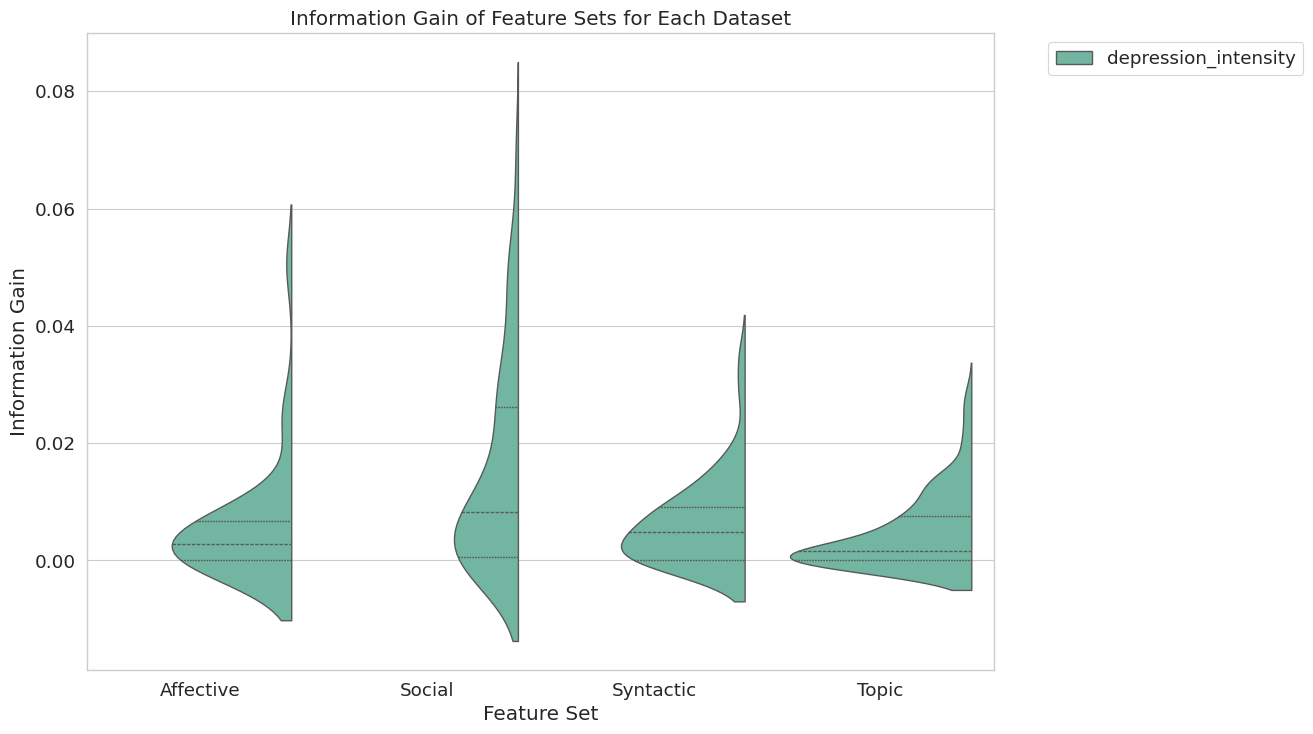

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import rcParams

# Set seaborn style, palette, and context
sns.set_style("whitegrid")
sns.set_palette("Set2")
sns.set_context("paper", font_scale=1.5)

# Set figure size
rcParams['figure.figsize'] = 11.7, 8.27

# Plot using seaborn violinplots
ax = sns.violinplot(x="feature_set", y="feature_ig", hue="dataset", data=results_inf, split=True, inner="quartile", linewidth=1)

# Set labels and title
ax.set_xlabel("Feature Set")
ax.set_ylabel("Information Gain")
ax.set_xticklabels(['Affective', 'Social', 'Syntactic', 'Topic'])
ax.set_title("Information Gain of Feature Sets for Each Dataset")

# Move the legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Save the plot
plt.savefig('/content/feature_information_gain_both.pdf', dpi=300)

# Show the plot
plt.show()


#Combining textual features with embeddings

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
# Load the dataset
data = pd.read_csv('/content/preprocessedData.csv')

In [ ]:
# Assuming the embeddings are in list format in the DataFrame
def extract_embeddings(df, column_name):
    return np.array(df[column_name].apply(eval).to_list())

In [ ]:
transformer_embeddings = extract_embeddings(data, 'transformer_embeddings')
ft_embeddings = extract_embeddings(data, 'ft_embeddings')
distil_roberta_embeddings = extract_embeddings(data, 'distil_roberta_embeddings')

In [ ]:
# Separate numeric features
numeric_features = data.drop(['text', 'transformer_embeddings', 'ft_embeddings', 'distil_roberta_embeddings', 'label'], axis=1)
target = data['label']

In [ ]:
# Normalize numeric features
scaler = StandardScaler()
numeric_features_scaled = scaler.fit_transform(numeric_features)

In [ ]:
# Combine features
combined_features = np.concatenate([
    numeric_features_scaled,
    transformer_embeddings,
    ft_embeddings,
    distil_roberta_embeddings
], axis=1)

In [ ]:
# Create TensorFlow Dataset
X_train, X_test, y_train, y_test = train_test_split(combined_features, target, test_size=0.2, random_state=42)
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).batch(32).shuffle(buffer_size=1024)
test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(32)

In [ ]:
# Build the model
model = tf.keras.Sequential([
    tf.keras.layers.InputLayer(input_shape=(combined_features.shape[1],)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')  # For binary classification; adjust output layer for different tasks
])

In [ ]:
# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
# Train the model
history = model.fit(train_dataset, epochs=50, validation_data=test_dataset)

Epoch 1/50
89/89 [==============================] - 2s 17ms/step - loss: -28803.4844 - accuracy: 0.5704 - val_loss: -14855.2842 - val_accuracy: 0.5499
Epoch 2/50
89/89 [==============================] - 1s 14ms/step - loss: -32021.8613 - accuracy: 0.5746 - val_loss: -16944.4551 - val_accuracy: 0.5527
Epoch 3/50
89/89 [==============================] - 1s 15ms/step - loss: -37234.6875 - accuracy: 0.5788 - val_loss: -19174.1289 - val_accuracy: 0.5513
Epoch 4/50
89/89 [==============================] - 1s 6ms/step - loss: -42199.1406 - accuracy: 0.5774 - val_loss: -21512.3340 - val_accuracy: 0.5527
Epoch 5/50
89/89 [==============================] - 1s 6ms/step - loss: -46330.5664 - accuracy: 0.5792 - val_loss: -23993.6172 - val_accuracy: 0.5541
Epoch 6/50
89/89 [==============================] - 1s 6ms/step - loss: -54060.9141 - accuracy: 0.5757 - val_loss: -26759.0469 - val_accuracy: 0.5513
Epoch 7/50
89/89 [==============================] - 1s 6ms/step - loss: -58998.7969 - accuracy: 0

In [ ]:
# Evaluate the model
loss, accuracy = model.evaluate(test_dataset)
print(f'Loss: {loss}, Accuracy: {accuracy}')

23/23 [==============================] - 0s 3ms/step - loss: -338163.8125 - accuracy: 0.5513
Loss: -338163.8125, Accuracy: 0.5513361692428589


using Random forest

In [ ]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [ ]:
combined_features.shape

(3553, 2333)

In [ ]:
# Perform PCA
n_components = 500
pca = PCA(n_components=n_components)
pca_features = pca.fit_transform(combined_features)

In [ ]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(pca_features, target, test_size=0.2, random_state=42)

In [ ]:
# Train a Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
# Predict on test set
y_pred = rf_classifier.predict(X_test)

In [ ]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.7173


Neural Network model

In [ ]:
# Perform PCA
n_components = 1500
pca = PCA(n_components=n_components)
pca_features = pca.fit_transform(combined_features)

In [ ]:
from sklearn.metrics import accuracy_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

In [ ]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(pca_features, target, test_size=0.2, random_state=42)

In [ ]:
# Define a neural network model
def create_model(input_dim):
    model = Sequential()
    model.add(Dense(128, input_dim=input_dim, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(64, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))  # Use 'softmax' for multi-class classification
    return model

In [ ]:
input_dim = X_train.shape[1]
model = create_model(input_dim)

In [ ]:
# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])  # Use 'sparse_categorical_crossentropy' for multi-class classification


In [ ]:
# Train the model
epochs = 50
batch_size = 32
history = model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.2)

Epoch 1/50
72/72 [==============================] - 2s 13ms/step - loss: 0.6689 - accuracy: 0.4567 - val_loss: 0.4663 - val_accuracy: 0.4956
Epoch 2/50
72/72 [==============================] - 1s 9ms/step - loss: 0.2695 - accuracy: 0.4778 - val_loss: -0.0949 - val_accuracy: 0.5360
Epoch 3/50
72/72 [==============================] - 1s 10ms/step - loss: -1.2531 - accuracy: 0.5130 - val_loss: -2.7287 - val_accuracy: 0.5782
Epoch 4/50
72/72 [==============================] - 1s 9ms/step - loss: -13.2248 - accuracy: 0.5649 - val_loss: -22.9172 - val_accuracy: 0.5413
Epoch 5/50
72/72 [==============================] - 0s 5ms/step - loss: -100.9672 - accuracy: 0.5733 - val_loss: -137.2286 - val_accuracy: 0.5659
Epoch 6/50
72/72 [==============================] - 0s 5ms/step - loss: -487.1131 - accuracy: 0.6010 - val_loss: -525.9531 - val_accuracy: 0.5712
Epoch 7/50
72/72 [==============================] - 0s 5ms/step - loss: -1621.3105 - accuracy: 0.6124 - val_loss: -1519.1143 - val_accuracy

In [ ]:
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Loss: {loss:.4f}, Accuracy: {accuracy:.4f}")

23/23 [==============================] - 0s 2ms/step - loss: -6124732.0000 - accuracy: 0.5387
Loss: -6124732.0000, Accuracy: 0.5387
